# v.0 Library Usability 

## Preprocessing: from event logs to session sequences

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import ast

In [7]:
import pandas as pd

sessions = pd.read_parquet(
    "../../data/processed/retailrocket_sessions.parquet"
)

sequences = sessions["events"].tolist()
print(sessions.head())
print(sequences)

   session  user                                            events  \
0        1     0                                [view, view, view]   
1        3     2  [view, view, view, view, view, view, view, view]   
2        7     6               [addtocart, view, view, view, view]   
3        9     7                                      [view, view]   
4       16    13                                      [view, view]   

       outcome  total_amount  n_events  
0  no_purchase           0.0         3  
1  no_purchase           0.0         8  
2  no_purchase           0.0         5  
3  no_purchase           0.0         2  
4  no_purchase           0.0         2  
[array(['view', 'view', 'view'], dtype=object), array(['view', 'view', 'view', 'view', 'view', 'view', 'view', 'view'],
      dtype=object), array(['addtocart', 'view', 'view', 'view', 'view'], dtype=object), array(['view', 'view'], dtype=object), array(['view', 'view'], dtype=object), array(['view', 'view'], dtype=object), array([

## Testing `BaselineAligner` (Stage 1: Levenshtein distance matrix)

### 0. Import the library
Install once from a terminal (folder containing `pyproject.toml`): `pip install -e .`

In [10]:
import sys
from pathlib import Path

# Add v0.2/ root to sys.path so `journey_analyzer` imports cleanly from notebooks/
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Top-level API import (tests journey_analyzer/__init__.py)
from journey_analyzer import BaselineAligner

# Sub-package pure function imports (tests journey_analyzer/alignment/__init__.py)
from journey_analyzer.alignment import (
    assign_stages,
    levenshtein_distance,
    normalized_levenshtein_distance,
    weighted_levenshtein_distance,
)

print("Successfully imported BaselineAligner and distance functions!")

Successfully imported BaselineAligner and distance functions!


In [11]:
import time
from journey_analyzer import BaselineAligner
from journey_analyzer.alignment import levenshtein_distance, normalized_levenshtein_distance

### 1. Sanity check on hand-made journeys
Before trusting 10,000 sessions we check the metric on cases where we know the answer.

In [12]:
a = ["login", "product_view", "add_to_cart", "purchase"]
b = ["login", "product_view", "purchase"]                  # a without 'add_to_cart'
c = ["logout", "click", "click", "page_view"]              # nothing in common with a

print("a vs a :", levenshtein_distance(a, a))                    # 0 -> identical
print("a vs b :", levenshtein_distance(a, b))                    # 1 -> one deletion
print("a vs c :", levenshtein_distance(a, c))                    # 4 -> four substitutions
print("a vs c normalized:", normalized_levenshtein_distance(a, c))  # 1.0 -> completely different

a vs a : 0.0
a vs b : 1.0
a vs c : 4.0
a vs c normalized: 1.0


### 2. Distance matrix on a random sample of 500 sessions (Experiment 1 scale)
We sample randomly (not `sequences[:500]`), because sessions are stored user by user and the first rows would all belong to the same few users.

In [43]:
rng = np.random.default_rng(42)
idx = rng.choice(len(sequences), size=500, replace=False)
sample = [sequences[i] for i in idx]
print("Sample randomly taken e.g: ", sample[:3])

aligner = BaselineAligner(metric="levenshtein")
t0 = time.perf_counter()
D = aligner.fit_distance_matrix(sample)
print(("\nResultant distance matrix:"))
print(D)
print(f"\nMatrix {D.shape} computed in {time.perf_counter() - t0:.1f} s")

Sample randomly taken e.g:  [array(['view', 'view', 'view', 'view', 'view', 'view', 'view', 'view',
       'view', 'view', 'view', 'view'], dtype=object), array(['view', 'view'], dtype=object), array(['view', 'view', 'view'], dtype=object)]

Resultant distance matrix:
[[ 0. 10.  9. ... 12. 11. 10.]
 [10.  0.  1. ...  3.  1.  0.]
 [ 9.  1.  0. ...  3.  2.  1.]
 ...
 [12.  3.  3. ...  0.  2.  3.]
 [11.  1.  2. ...  2.  0.  1.]
 [10.  0.  1. ...  3.  1.  0.]]

Matrix (500, 500) computed in 0.8 s


### 3. Are the matrix properties right?

In [14]:
print("symmetric       :", np.allclose(D, D.T))
print("zero diagonal   :", bool(np.all(np.diag(D) == 0))) # each journey is identical to itself 
print("non-negative    :", bool(D.min() >= 0))

upper = D[np.triu_indices_from(D, k=1)]          # each pair counted once
print(f"pairs: {len(upper):,} | min {upper.min():.0f} | mean {upper.mean():.2f} | max {upper.max():.0f}")
print("read-only matrix:", not D.flags.writeable)

# Very important to check... if not we have a bug in the code or enormous error in the data 

symmetric       : True
zero diagonal   : True
non-negative    : True
pairs: 124,750 | min 0 | mean 2.81 | max 40
read-only matrix: True


### 4. Distribution of distances
If the data had real behavioural groups we would expect several bumps (small distances inside a group, large between groups).

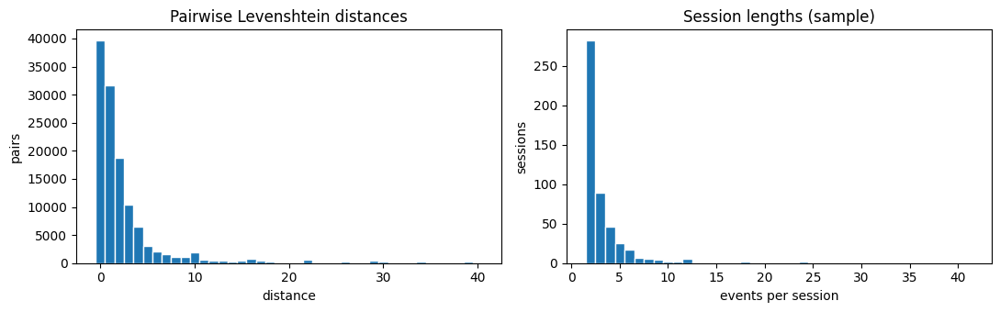

In [44]:
lens = np.array([len(s) for s in sample])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(upper, bins=np.arange(upper.min(), upper.max() + 2) - 0.5, edgecolor="white")
ax[0].set(title="Pairwise Levenshtein distances", xlabel="distance", ylabel="pairs")
ax[1].hist(lens, bins=np.arange(lens.min(), lens.max() + 2) - 0.5, edgecolor="white")
ax[1].set(title="Session lengths (sample)", xlabel="events per session", ylabel="sessions")
plt.tight_layout(); plt.show()

### 5. Look at actual journeys: closest vs. farthest pair

In [45]:
M = D.copy(); np.fill_diagonal(M, np.inf)
i, j = np.unravel_index(M.argmin(), M.shape)
print("MOST SIMILAR pair, distance", D[i, j]); print("  ", sample[i]); print("  ", sample[j])

M = D.copy(); np.fill_diagonal(M, -np.inf)
i, j = np.unravel_index(M.argmax(), M.shape)
print("\nMOST DIFFERENT pair, distance", D[i, j]); print("  ", sample[i]); print("  ", sample[j])

MOST SIMILAR pair, distance 0.0
   ['view' 'view' 'view' 'view' 'view' 'view' 'view' 'view' 'view' 'view'
 'view' 'view']
   ['view' 'view' 'view' 'view' 'view' 'view' 'view' 'view' 'view' 'view'
 'view' 'view']

MOST DIFFERENT pair, distance 40.0
   ['addtocart' 'addtocart' 'addtocart']
   ['view' 'view' 'view' 'view' 'view' 'view' 'view' 'view' 'view' 'view'
 'view' 'view' 'view' 'view' 'addtocart' 'view' 'view' 'view' 'view'
 'view' 'view' 'view' 'view' 'view' 'view' 'view' 'view' 'view' 'view'
 'view' 'view' 'view' 'view' 'view' 'view' 'view' 'view' 'view' 'view'
 'view' 'view']


### 6. Weighted metric (stage-aware)
Stages follow Kinjo (2025): pre-purchase, purchase, post-purchase. Here the purchase stage counts 3x.

Testing different weights:

In [46]:
STAGES = {
    "view": "pre",
    "addtocart": "cart",
    "transaction": "purchase"
}

# 1. Baseline: no additional weights
weights_1 = {}

# 2. Purchase receives greater importance
weights_2 = {"purchase": 4.0}

# 3. Progressive purchase-intent weighting
weights_3 = {
    "cart": 2.0,
    "purchase": 4.0
}

In [47]:
from scipy.stats import spearmanr

upper = D[np.triu_indices_from(D, k=1)]

configurations = {
    "Plain": {},
    "Purchase x4": {"purchase": 4.0},
    "Cart x2 + Purchase x4": {
        "cart": 2.0,
        "purchase": 4.0
    }
}

results = []

for name, weights in configurations.items():

    aligner_w = BaselineAligner(
        "weighted",
        stage_weights=weights,
        event_to_stage=STAGES
    )

    D_test = aligner_w.fit_distance_matrix(sample)
    upper_test = D_test[np.triu_indices_from(D_test, k=1)]

    results.append({
        "Configuration": name,
        "Mean distance": upper_test.mean(),
        "Std distance": upper_test.std(),
        "Spearman vs plain": spearmanr(
            upper, upper_test
        ).statistic
    })

results_df = pd.DataFrame(results)
display(results_df.round(3))

,Configuration,Mean distance,Std distance,Spearman vs plain
0,Plain,2.934,5.294,0.988
1,Purchase x4,3.099,5.419,0.979
2,Cart x2 + Purchase x4,3.344,5.591,0.963


We see that it orders the pairs following the same distribution. The weighting changes the magnitude of distances, but it does not substantially change which sessions are considered more or less similar.

But the mean of the distances is now higher, separating more the journeys if there was a purchase or not.

### 7. Runtime growth

seconds: [0.01, 0.03, 0.11, 0.45] | estimated exponent: 1.81
Extrapolation to all 386,033 sessions: ~7015.1 minutes


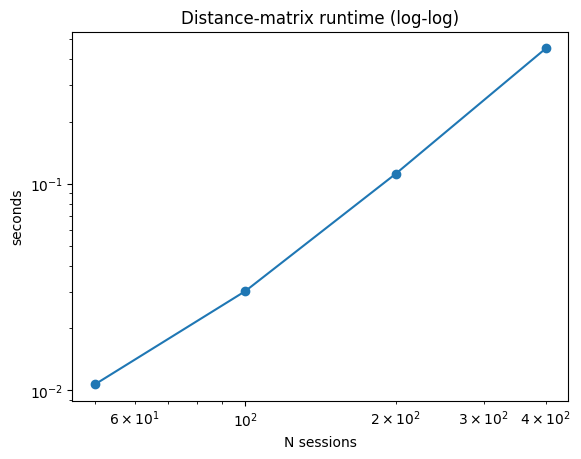

In [48]:
sizes = [50, 100, 200, 400]
times = []
for n in sizes:
    t0 = time.perf_counter()
    BaselineAligner().fit_distance_matrix(sample[:n])
    times.append(time.perf_counter() - t0)

slope = np.polyfit(np.log(sizes), np.log(times), 1)[0]     # slope of log-log line = exponent
print("seconds:", [round(t, 2) for t in times], "| estimated exponent:", round(slope, 2))

n_all = len(sequences)
est_h = times[-1] * (n_all / sizes[-1]) ** 2 / 3600
print(f"Extrapolation to all {n_all:,} sessions: ~{est_h*60:.1f} minutes")

plt.loglog(sizes, times, "o-"); plt.xlabel("N sessions"); plt.ylabel("seconds")
plt.title("Distance-matrix runtime (log-log)"); plt.show()

So the runtime is quadratic as in theory.

### 8. Memory guard CHECK THIS
The aligner refuses to allocate a matrix above `max_matrix_gb`, before it starts computing.

In [49]:

try:
    BaselineAligner(max_matrix_gb=0.1).fit_distance_matrix(sequences) 
except MemoryError as e:
    print("MemoryError:", e)

MemoryError: A 386033 x 386033 float32 distance matrix needs ~596.1 GB (limit 0.1 GB). Use a subsample or switch to the O(N) methods (k-grams / LDA / SBERT).


## Prototype extraction with k-medoids (PAM)
A **medoid** is the real session with the smallest total distance to the other sessions of its cluster, so each prototype is an actual user journey. We first run a **control experiment** on data where we know the groups exist, to prove the algorithm works. Then we run it on the real sample.

### 9. Control experiment: planted journey types
Three journey templates (buyer, browser, bouncer) with random edits (deletions, substitutions, insertions). PAM should recover them.

In [50]:
templates = {
    "buyer":   ["login", "product_view", "add_to_cart", "purchase", "logout"],
    "browser": ["login", "page_view", "click", "click", "page_view", "logout"],
    "bouncer": ["login", "product_view", "product_view", "product_view", "logout"],
}
all_events = sorted({e for t in templates.values() for e in t})
rng_c = np.random.default_rng(0)

def noisy(template, p=0.15):
    out = []
    for e in template:
        r = rng_c.random()
        if r < p / 3:   continue                                  # delete the event
        if r < 2*p / 3: out.append(str(rng_c.choice(all_events))); continue   # substitute it
        if r < p:       out.append(str(rng_c.choice(all_events)))              # insert one before it
        out.append(e)
    return out

planted, truth = [], []
for name, t in templates.items():
    for _ in range(150):
        planted.append(noisy(t)); truth.append(name)

al_planted = BaselineAligner()
al_planted.fit_distance_matrix(planted)
res_p = al_planted.extract_prototypes(k=3)

print(pd.crosstab(pd.Series(truth, name="true type"), pd.Series(res_p["labels"], name="found cluster")))
for c, (size, proto) in enumerate(zip(res_p["sizes"], res_p["prototypes"])):
    print(f"cluster {c} ({size} sessions) prototype: {proto}")
print("silhouette:", round(al_planted.silhouette_score(), 3), "| swaps:", res_p["n_iter"], "| converged:", res_p["converged"])

found cluster    0    1    2
true type                   
bouncer          8    0  142
browser          1  149    0
buyer          150    0    0
cluster 0 (159 sessions) prototype: ['login', 'product_view', 'add_to_cart', 'purchase', 'logout']
cluster 1 (149 sessions) prototype: ['login', 'page_view', 'click', 'click', 'page_view', 'logout']
cluster 2 (142 sessions) prototype: ['login', 'product_view', 'product_view', 'product_view', 'logout']
silhouette: 0.559 | swaps: 0 | converged: True


### 10. k-medoids on the real sample (k = 4)

inertia 313 | swaps 2 | converged True | silhouette 0.672
cluster 0: 301 sessions | prototype (2 events): ['view' 'view']
cluster 1: 118 sessions | prototype (3 events): ['view' 'view' 'view']
cluster 2:  69 sessions | prototype (6 events): ['view' 'view' 'view' 'view' 'view' 'view']
cluster 3:  12 sessions | prototype (24 events): ['view' 'view' 'view' 'view' 'view' 'view' 'view' 'view' 'view' 'view'
 'view' 'view' 'view' 'view' 'view' 'view' 'view' 'view' 'view' 'view'
 'view' 'view' 'view' 'view']


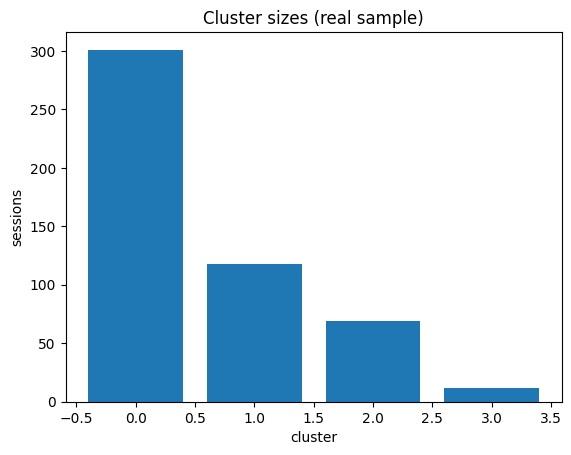

In [51]:
res = aligner.extract_prototypes(k=4)

print(f"inertia {res['inertia']:.0f} | swaps {res['n_iter']} | converged {res['converged']} "
      f"| silhouette {aligner.silhouette_score():.3f}")
for c, (size, proto) in enumerate(zip(res["sizes"], res["prototypes"])):
    print(f"cluster {c}: {size:>3} sessions | prototype ({len(proto)} events): {proto}")

plt.bar(range(4), res["sizes"]); plt.xlabel("cluster"); plt.ylabel("sessions")
plt.title("Cluster sizes (real sample)"); plt.show()

inertia 454 | swaps 2 | converged True | silhouette 0.559
cluster 0: 301 sessions | prototype (2 events): ['view' 'view']
cluster 1: 122 sessions | prototype (3 events): ['view' 'view' 'view']
cluster 2:  65 sessions | prototype (6 events): ['view' 'view' 'view' 'view' 'view' 'view']
cluster 3:  12 sessions | prototype (24 events): ['view' 'view' 'view' 'view' 'view' 'view' 'view' 'view' 'view' 'view'
 'view' 'view' 'view' 'view' 'view' 'view' 'view' 'view' 'view' 'view'
 'view' 'view' 'view' 'view']


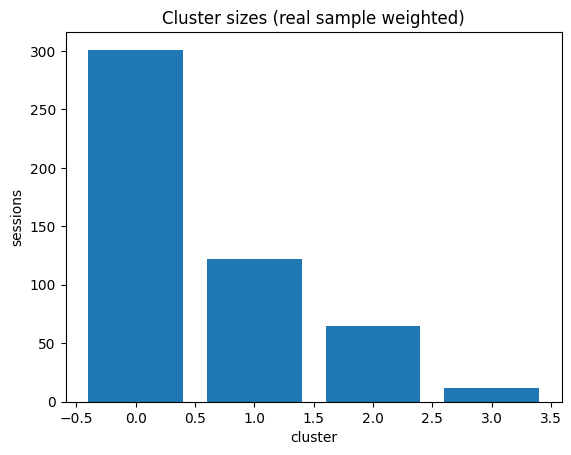

In [52]:
res = aligner_w.extract_prototypes(k=4)

print(f"inertia {res['inertia']:.0f} | swaps {res['n_iter']} | converged {res['converged']} "
      f"| silhouette {aligner_w.silhouette_score():.3f}")
for c, (size, proto) in enumerate(zip(res["sizes"], res["prototypes"])):
    print(f"cluster {c}: {size:>3} sessions | prototype ({len(proto)} events): {proto}")

plt.bar(range(4), res["sizes"]); plt.xlabel("cluster"); plt.ylabel("sessions")
plt.title("Cluster sizes (real sample weighted)"); plt.show()

### 11. How many clusters? Inertia and silhouette for k = 2..10
Inertia always decreases with k, so look for an elbow. Silhouette should peak at the natural number of groups (3 in the control experiment).

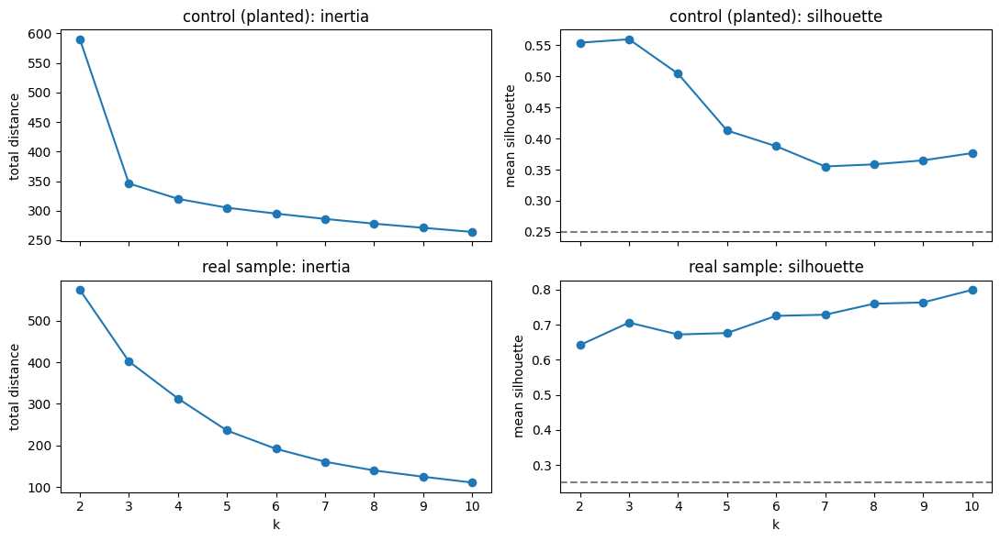

In [ ]:
ks = range(2, 11)
def sweep(al):
    inertia, sil = [], []
    for k in ks:
        r = al.extract_prototypes(k)
        inertia.append(r["inertia"]); sil.append(al.silhouette_score())
    return inertia, sil

fig, ax = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
for row, (name, al) in enumerate([("control (planted)", al_planted), ("real sample", aligner)]):
    inertia, sil = sweep(al)
    ax[row, 0].plot(list(ks), inertia, "o-"); ax[row, 0].set(title=f"{name}: inertia", ylabel="total distance")
    ax[row, 1].plot(list(ks), sil, "o-");     ax[row, 1].set(title=f"{name}: silhouette", ylabel="mean silhouette")
    ax[row, 1].axhline(0.25, ls="--", c="grey")      # below this: no substantial structure
ax[1, 0].set_xlabel("k"); ax[1, 1].set_xlabel("k")
plt.tight_layout(); plt.show()

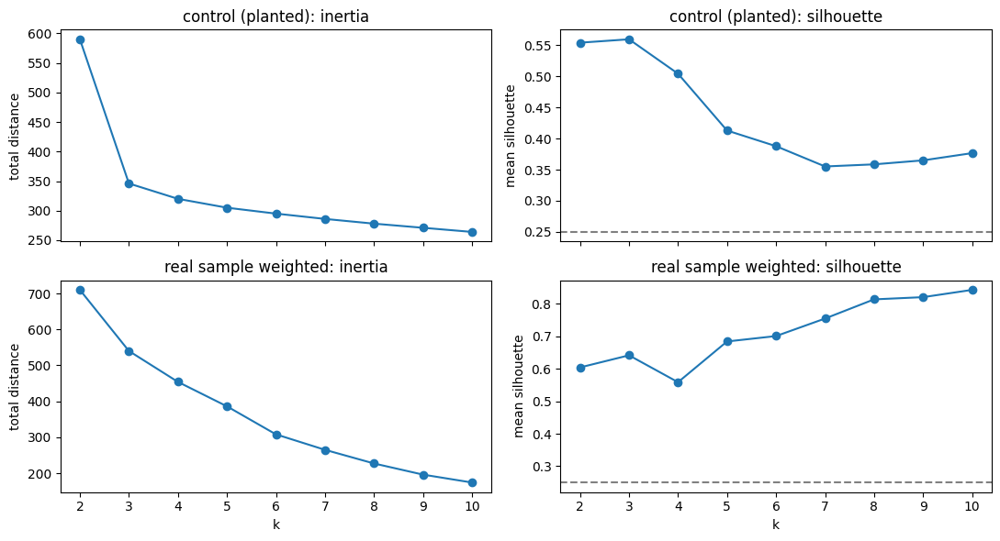

In [55]:
ks = range(2, 11)
def sweep(al):
    inertia, sil = [], []
    for k in ks:
        r = al.extract_prototypes(k)
        inertia.append(r["inertia"]); sil.append(al.silhouette_score())
    return inertia, sil

fig, ax = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
for row, (name, al) in enumerate([("control (planted)", al_planted), ("real sample weighted", aligner_w)]):
    inertia, sil = sweep(al)
    ax[row, 0].plot(list(ks), inertia, "o-"); ax[row, 0].set(title=f"{name}: inertia", ylabel="total distance")
    ax[row, 1].plot(list(ks), sil, "o-");     ax[row, 1].set(title=f"{name}: silhouette", ylabel="mean silhouette")
    ax[row, 1].axhline(0.25, ls="--", c="grey")      # below this: no substantial structure
ax[1, 0].set_xlabel("k"); ax[1, 1].set_xlabel("k")
plt.tight_layout(); plt.show()

The algorithm works perfectly, but strict sequential alignment is not the right fit for your real data (WITHOUTH WEIGHTED DISTANCE)

There is no existing underlaying structure to be found. 

Because the real user journeys are clearly too noisy or non-linear for Levenshtein distance, optimizing k further will not yield better results. Transitioning away from strict edit distances toward other methods could be more useful.

### 12. Do the weighted-metric prototypes differ?
Same sessions, but the purchase stage counts (`aligner_w` in section 6).

In [58]:
# Event-to-stage mapping
STAGES = {
    "view": "pre",
    "addtocart": "cart",
    "transaction": "purchase"
}

# Weight configurations to compare
weight_configs = {
    "Plain": {},
    "Purchase x4": {"purchase": 4.0},
    "Cart x2 + Purchase x4": {
        "cart": 2.0,
        "purchase": 4.0
    }
}

# Store results
aligners = {"Plain": aligner}
cluster_results = {}
comparison = []

# Baseline labels
plain_labels = aligner.labels_

# Test each configuration
for name, weights in weight_configs.items():

    if name == "Plain":
        current_aligner = aligner
    else:
        current_aligner = BaselineAligner(
            "weighted",
            stage_weights=weights,
            event_to_stage=STAGES
        )

        current_aligner.fit_distance_matrix(sample)

    # Extract prototypes
    res = current_aligner.extract_prototypes(k=4)

    # Store aligner and results
    aligners[name] = current_aligner
    cluster_results[name] = res

    # Calculate agreement with plain clustering
    agreement = (
        current_aligner.labels_ == plain_labels
    ).mean()

    # Store metrics
    comparison.append({
        "Configuration": name,
        "Silhouette": current_aligner.silhouette_score(),
        "Mean cluster size": np.mean(res["sizes"]),
        "Assignment agreement": agreement
    })

    # Display prototypes
    print(f"\n{'='*60}")
    print(f"CONFIGURATION: {name}")
    print(f"Stage weights: {weights}")
    print(f"Silhouette: {current_aligner.silhouette_score():.3f}")

    for c, (size, proto) in enumerate(
        zip(res["sizes"], res["prototypes"])
    ):
        print(
            f"Cluster {c}: {size:>5} sessions | "
            f"prototype: {proto}"
        )

    # Crosstab against plain clustering
    if name != "Plain":
        agree = pd.crosstab(
            pd.Series(plain_labels, name="plain"),
            pd.Series(
                current_aligner.labels_,
                name=name
            )
        )

        print("\nCluster agreement with plain:")
        display(agree)


# Final comparison table
comparison_df = pd.DataFrame(comparison)

print("\nFINAL COMPARISON")
display(comparison_df.round(3))



CONFIGURATION: Plain
Stage weights: {}
Silhouette: 0.672
Cluster 0:   301 sessions | prototype: ['view' 'view']
Cluster 1:   118 sessions | prototype: ['view' 'view' 'view']
Cluster 2:    69 sessions | prototype: ['view' 'view' 'view' 'view' 'view' 'view']
Cluster 3:    12 sessions | prototype: ['view' 'view' 'view' 'view' 'view' 'view' 'view' 'view' 'view' 'view'
 'view' 'view' 'view' 'view' 'view' 'view' 'view' 'view' 'view' 'view'
 'view' 'view' 'view' 'view']

CONFIGURATION: Purchase x4
Stage weights: {'purchase': 4.0}
Silhouette: 0.615
Cluster 0:   301 sessions | prototype: ['view' 'view']
Cluster 1:   122 sessions | prototype: ['view' 'view' 'view']
Cluster 2:    65 sessions | prototype: ['view' 'view' 'view' 'view' 'view' 'view']
Cluster 3:    12 sessions | prototype: ['view' 'view' 'view' 'view' 'view' 'view' 'view' 'view' 'view' 'view'
 'view' 'view' 'view' 'view' 'view' 'view' 'view' 'view' 'view' 'view'
 'view' 'view' 'view' 'view']

Cluster agreement with plain:


Purchase x4,0,1,2,3
plain,,,,
0,301,0,0,0
1,0,45,49,0
2,0,77,0,0
3,0,0,16,5
4,0,0,0,7



CONFIGURATION: Cart x2 + Purchase x4
Stage weights: {'cart': 2.0, 'purchase': 4.0}
Silhouette: 0.559
Cluster 0:   301 sessions | prototype: ['view' 'view']
Cluster 1:   122 sessions | prototype: ['view' 'view' 'view']
Cluster 2:    65 sessions | prototype: ['view' 'view' 'view' 'view' 'view' 'view']
Cluster 3:    12 sessions | prototype: ['view' 'view' 'view' 'view' 'view' 'view' 'view' 'view' 'view' 'view'
 'view' 'view' 'view' 'view' 'view' 'view' 'view' 'view' 'view' 'view'
 'view' 'view' 'view' 'view']

Cluster agreement with plain:


Cart x2 + Purchase x4,0,1,2,3
plain,,,,
0,301,0,0,0
1,0,45,49,0
2,0,77,0,0
3,0,0,16,5
4,0,0,0,7



FINAL COMPARISON


,Configuration,Silhouette,Mean cluster size,Assignment agreement
0,Plain,0.672,125.0,0.694
1,Purchase x4,0.615,125.0,0.702
2,Cart x2 + Purchase x4,0.559,125.0,0.702


The sihouette is better when not using weighted distances in this dataset

In [64]:
from sklearn.metrics import adjusted_rand_score

for name, current_aligner in aligners.items():
    if name != "Plain":
        ari = adjusted_rand_score(
            plain_labels,
            current_aligner.labels_
        )
        print(f"{name}: ARI = {ari:.3f}")

Purchase x4: ARI = 0.893
Cart x2 + Purchase x4: ARI = 0.893


ARI stands for Adjusted Rand Index, a metric used to measure how similar two clustering solutions are. 

Compares the assigment of pairs of observations across two clustering solutions. Checks wether metrhods agree on wheter sessions belong together or separately. An ARI of 1.0 means perfect agreement (it goes from -1 to +1).

In this case: An ARI of 0.893 indicates that the weighted and unweighted solutions agree strongly on which pairs of sessions belong together or separately. The additional cart weighting has relatively little influence compared with the transaction weighting.

## Visualizing the clusters
`plot_clusters` projects the sessions to 2D with MDS (so that close sessions in the distance matrix are close on the plot) and draws:
- **Left:** sessions coloured by cluster, medoids as stars, faint lines from every session to its medoid.
- **Right:** the same points coloured by each session's own **silhouette** (green = well inside its cluster, red = misplaced).

The title reports how faithful the 2D picture is (*stress*: lower is better). Many sessions are identical journeys and would overlap exactly, so points are jittered slightly for display.

### 13. Control experiment: three planted journey types

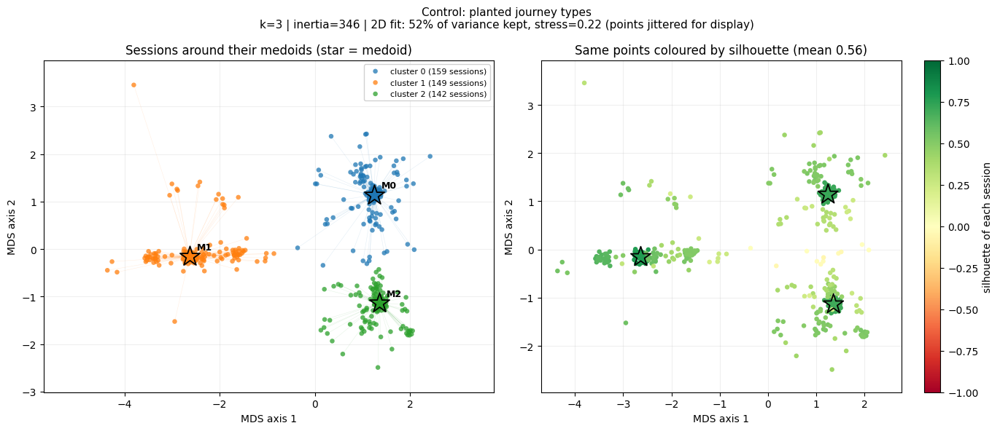

In [59]:
al_planted.extract_prototypes(k=3)            # earlier cells left this object with k=10
fig, X_planted = al_planted.plot_clusters(title="Control: planted journey types")
plt.show()

### 15. Real sample (k = 4)

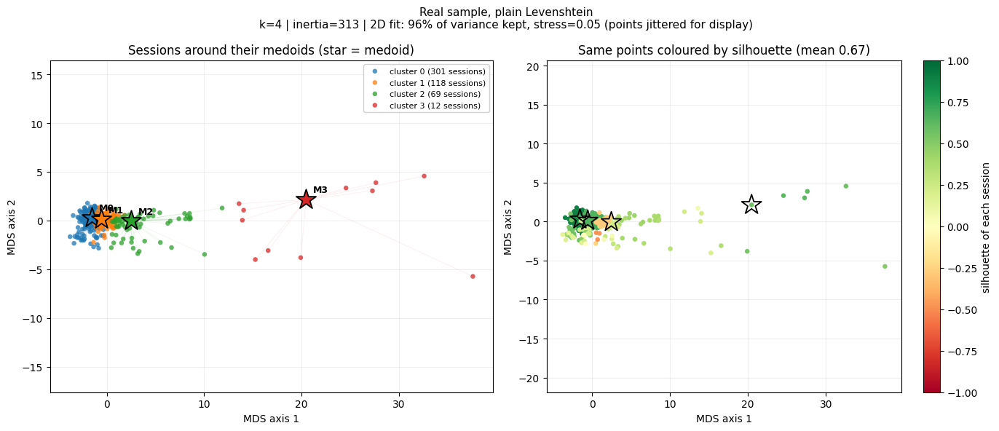

In [60]:
aligner.extract_prototypes(k=4)               # earlier cells left this object with another k
fig, X_sample = aligner.plot_clusters(title="Real sample, plain Levenshtein")
plt.show()

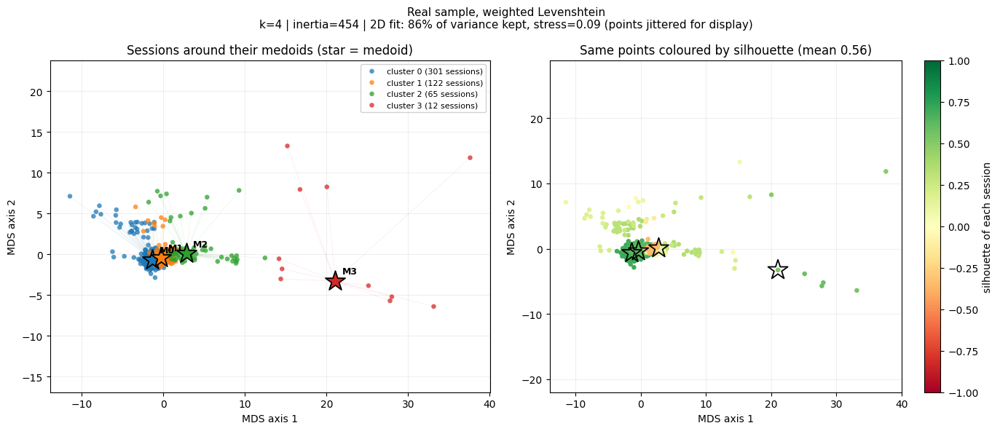

In [61]:
fig, X_sample = aligner_w.plot_clusters(title="Real sample, weighted Levenshtein")
plt.show()

### 16. How many sessions are probably misplaced?
Sessions with a negative silhouette are closer, on average, to another cluster than to their own.

In [63]:
from journey_analyzer.alignment import silhouette_samples_from_distances

for name, al in [("control", al_planted), ("real sample", aligner_w)]:
    s = silhouette_samples_from_distances(al.distance_matrix, al.labels_)
    print(f"{name:12s} mean {s.mean():+.2f} | negative: {(s < 0).mean():5.1%} | above 0.5: {(s > 0.5).mean():5.1%}")

control      mean +0.56 | negative:  2.2% | above 0.5: 69.8%
real sample  mean +0.56 | negative:  5.0% | above 0.5: 77.4%
